In [6]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from matplotlib.ticker import ticker, FormatStrFormatter, FuncFormatter, FixedLocator, ScalarFormatter
from matplotlib.colors import LogNorm, TwoSlopeNorm, Normalize
from IPython.display import display, Math
from dataclasses import dataclass
from typing import List, Optional, Tuple

In [7]:
display(Math(r"""
\begin{align}
r_{\text{ceiling}} &= \frac{2 r_{\text{half}}}{1 + r_{\text{half}}} \tag{1} \\[2.5em]
\text{MSE}_{r_{\text{unbiased}}} &< \text{MSE}_{r} \tag{2} \\[1.5em]
\frac{\text{MSE}_{r_{\text{unbiased}}}}{\text{MSE}_{r}} &< 1 \tag{3} \\[1.5em]
\widehat{\text{RMSE}}_{r} &= \widehat{\text{Var}}(r) + \widehat{\text{Bias}}(r)^2 \tag{2} \\[0.5em]
&= \frac{(1 - r^2)^2}{N - 1} + \left(\frac{r}{r_{\text{ceiling}}} - r\right)^2 \nonumber \\[2.5em]
\widehat{\text{RMSE}}_{r_{\text{unbiased}}} &= \frac{\widehat{\text{Var}}(r)}{r_{\text{ceiling}}^2} \tag{3} \\[1.5em]
&= \frac{(1 - r^2)^2}{r_{\text{ceiling}}^2 (N - 1)} \nonumber
\end{align}
"""))

<IPython.core.display.Math object>

In [8]:
display(Math(r"""
\begin{align}
\text{MSE}_{R} &\approx \text{Var}(R) + \left(R - \rho\right)^2 \\[1em]
\text{MSE}_{R_\text{unbiased}} &\approx \frac{\text{Var}(R)}{R_{\text{ceiling}}^2}
\end{align}
"""))

display(Math(r"\text{where } \text{Var}(R) \approx \frac{(1 - R^2)^2}{N - 1} \quad \text{and} \quad \rho \approx \frac{R}{R_{\text{ceiling}}}. "))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Running condition 1/15: N=15, repeats=2


/var/folders/tv/bsvxxkg10s71322nv0drgww00000gn/T/ipykernel_45405/514011780.py:44: RuntimeWarning: invalid value encountered in sqrt
  attenuation = np.sqrt(compute_reliability(m1) * compute_reliability(m2))


Running condition 2/15: N=15, repeats=4
Running condition 3/15: N=15, repeats=6
Running condition 4/15: N=30, repeats=2
Running condition 5/15: N=30, repeats=4
Running condition 6/15: N=30, repeats=6
Running condition 7/15: N=60, repeats=2
Running condition 8/15: N=60, repeats=4
Running condition 9/15: N=60, repeats=6
Running condition 10/15: N=120, repeats=2
Running condition 11/15: N=120, repeats=4
Running condition 12/15: N=120, repeats=6
Running condition 13/15: N=240, repeats=2
Running condition 14/15: N=240, repeats=4
Running condition 15/15: N=240, repeats=6


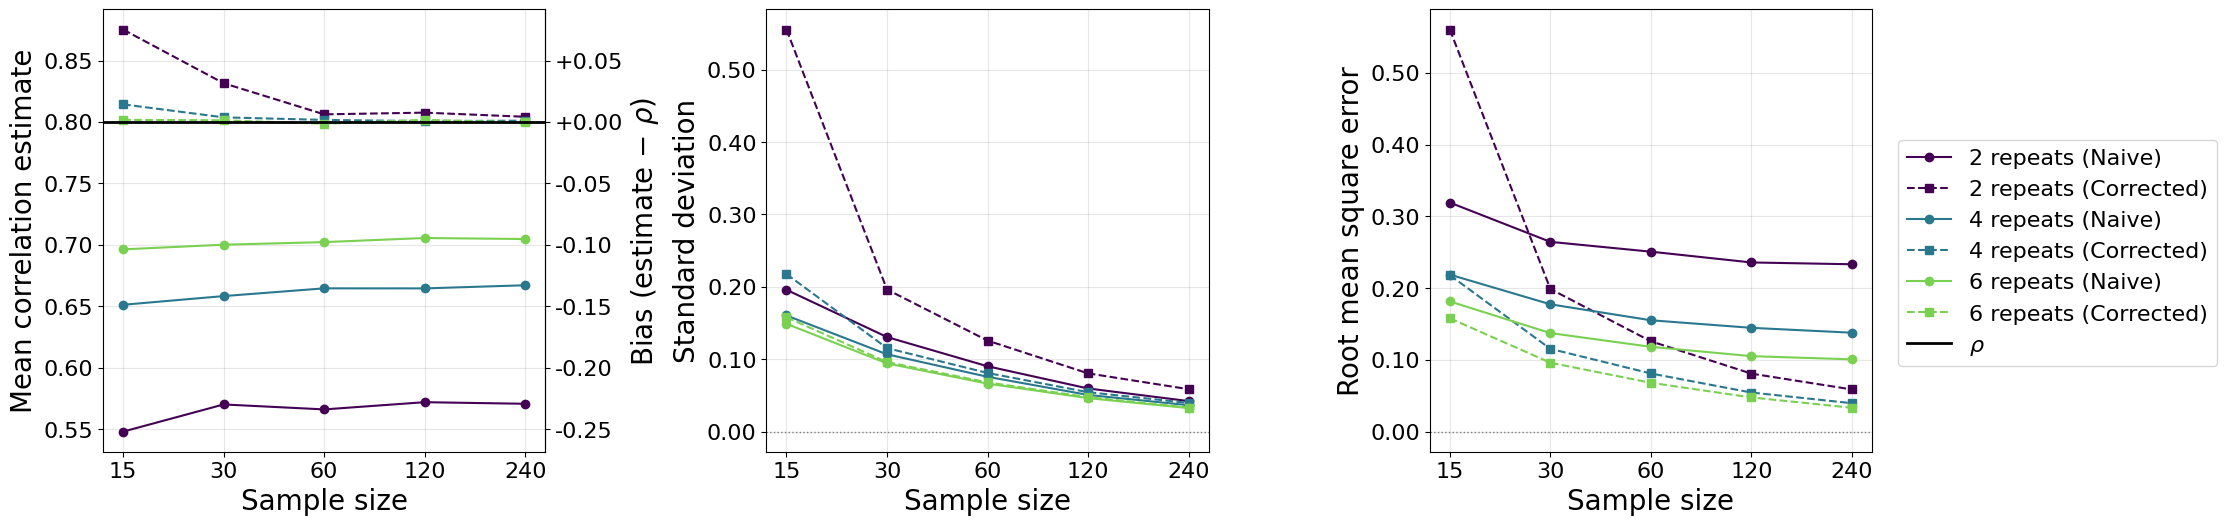

Saved figure to simulation_summary.png


In [23]:
@dataclass
class TaskParameters:
    between_var: float  # true individual differences
    within_var: float   # measurement noise
    mean: float = 0.0
    name: str = "task"


def compute_reliability(measurements: np.ndarray) -> float:
    k = measurements.shape[1]
    var_means = measurements.mean(axis=1).var(ddof=1)
    within_var = measurements.var(axis=1, ddof=1).mean()
    if var_means <= 0:
        return np.nan
    return 1 - (within_var / k) / var_means   # = σ²_true / (σ²_true + σ²_within/k)


def simulate_data(task1, task2, n_subjects, n_repeats, true_correlation, rng):
    """Return two (n_subjects, n_repeats) arrays of noisy measurements."""
    cov_xy = true_correlation * np.sqrt(task1.between_var * task2.between_var)
    cov = [[task1.between_var, cov_xy], [cov_xy, task2.between_var]]
    true = rng.multivariate_normal([task1.mean, task2.mean], cov, size=n_subjects)
    m1 = true[:, [0]] + rng.normal(0, np.sqrt(task1.within_var), (n_subjects, n_repeats))
    m2 = true[:, [1]] + rng.normal(0, np.sqrt(task2.within_var), (n_subjects, n_repeats))
    return m1, m2


def run_simulation(task1, task2, n_subjects, n_repeats, true_correlation, n_iterations, rng):
    naive = np.empty(n_iterations)
    corrected = np.empty(n_iterations)

    for it in range(n_iterations):
        m1, m2 = simulate_data(task1, task2, n_subjects, n_repeats, true_correlation, rng)
        r, _ = pearsonr(m1.mean(axis=1), m2.mean(axis=1))
        attenuation = np.sqrt(compute_reliability(m1) * compute_reliability(m2))
        naive[it] = r
        corrected[it] = r / attenuation if attenuation > 0 else np.nan

    corrected = corrected[~np.isnan(corrected)]
    rmse = lambda x: np.sqrt(np.mean((x - true_correlation) ** 2))

    return {
        'naive_mean': naive.mean(),
        'naive_sd': naive.std(),
        'naive_rmse': rmse(naive),
        'corrected_mean': corrected.mean(),
        'corrected_sd': corrected.std(),
        'corrected_rmse': rmse(corrected),
    }


def run_simulation_grid(
    task1, task2,
    sample_sizes: List[int],
    n_repeats_list: List[int],
    true_correlation: float,
    n_iterations: int = 500,
    random_state: Optional[int] = None,
) -> pd.DataFrame:
    rng = np.random.default_rng(random_state)
    rows = []
    total = len(sample_sizes) * len(n_repeats_list)
    for n_subjects in sample_sizes:
        for n_repeats in n_repeats_list:
            print(f"Running condition {len(rows) + 1}/{total}: N={n_subjects}, repeats={n_repeats}")
            stats = run_simulation(task1, task2, n_subjects, n_repeats,
                                   true_correlation, n_iterations, rng)
            rows.append({'n_subjects': n_subjects, 'n_repeats': n_repeats, **stats})
    return pd.DataFrame(rows)


def plot_simulation_summary(
    results_df: pd.DataFrame,
    true_correlation: float = 0.4,
    figsize: Tuple[int, int] = (22, 7),
    save_path: Optional[str] = None,
) -> plt.Figure:
    fig, axes = plt.subplots(1, 3, figsize=figsize)

    sample_sizes = sorted(results_df['n_subjects'].unique())
    n_repeats_list = sorted(results_df['n_repeats'].unique())
    colors = plt.cm.viridis(np.linspace(0, 0.8, len(n_repeats_list)))

    label_size = 20
    tick_size = 16

    def style_axis(ax, ylabel):
        ax.set_xlabel('Sample size', fontsize=label_size)
        ax.set_ylabel(ylabel, fontsize=label_size)
        ax.tick_params(axis='both', labelsize=tick_size)
        ax.set_xscale('log')
        ax.set_xticks(sample_sizes)
        ax.set_xticklabels(sample_sizes)
        ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
        ax.minorticks_off()
        ax.set_box_aspect(1)
        ax.grid(True, alpha=0.3)

    def plot_metric(ax, naive_col, corrected_col, label=False):
        for i, n_rep in enumerate(n_repeats_list):
            subset = results_df[results_df['n_repeats'] == n_rep].sort_values('n_subjects')
            ax.plot(subset['n_subjects'], subset[naive_col], '-o', color=colors[i],
                    label=f'{n_rep} repeats (Naive)' if label else None)
            ax.plot(subset['n_subjects'], subset[corrected_col], '--s', color=colors[i],
                    label=f'{n_rep} repeats (Corrected)' if label else None)

    # Left: mean estimates + bias axis
    ax = axes[0]
    plot_metric(ax, 'naive_mean', 'corrected_mean', label=True)
    ax.axhline(true_correlation, color='black', linestyle='-', linewidth=2, label=r'$\rho$')
    style_axis(ax, 'Mean correlation estimate')
    bias_ax = ax.secondary_yaxis(
        'right',
        functions=(lambda y: y - true_correlation, lambda b: b + true_correlation),
    )
    bias_ax.set_ylabel(r'Bias (estimate $-\ \rho$)', fontsize=label_size)
    bias_ax.tick_params(axis='y', labelsize=tick_size)
    bias_ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%+.2f'))
    handles, labels = ax.get_legend_handles_labels()

    # Middle: SD
    ax = axes[1]
    plot_metric(ax, 'naive_sd', 'corrected_sd')
    ax.axhline(0, color='gray', linestyle=':', linewidth=1)
    style_axis(ax, 'Standard deviation')

    # Right: RMSE
    ax = axes[2]
    plot_metric(ax, 'naive_rmse', 'corrected_rmse')
    ax.axhline(0, color='gray', linestyle=':', linewidth=1)
    style_axis(ax, 'Root mean square error')

    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.86, 0.5), fontsize=16)
    plt.tight_layout(rect=[0, 0, 0.86, 1])
    fig.subplots_adjust(wspace=0.5)  # smaller = closer panels

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    return fig


# ---------------------------------------------------------------------------
# Usage
# ---------------------------------------------------------------------------
true_correlation = 0.8

task1_params = TaskParameters(between_var=0.5, within_var=0.4, mean=0, name='task1')
task2_params = TaskParameters(between_var=0.5, within_var=0.4, mean=0, name='task2')

grid_results = run_simulation_grid(
    task1_params, task2_params,
    sample_sizes=[15, 30, 60, 120, 240],
    n_repeats_list=[2, 4, 6],
    true_correlation=true_correlation,
    n_iterations=1000,
    random_state=None,
)

png_path = 'simulation_summary.png'
fig = plot_simulation_summary(grid_results, true_correlation=true_correlation,
                              save_path=png_path)
plt.show()
print(f"Saved figure to {png_path}")

# If running in Google Colab, also trigger a browser download:
try:
    from google.colab import files
    files.download(png_path)
except ImportError:
    pass  # local Python / Jupyter: the PNG is already in your working directory

/var/folders/tv/bsvxxkg10s71322nv0drgww00000gn/T/ipykernel_45405/1152863199.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


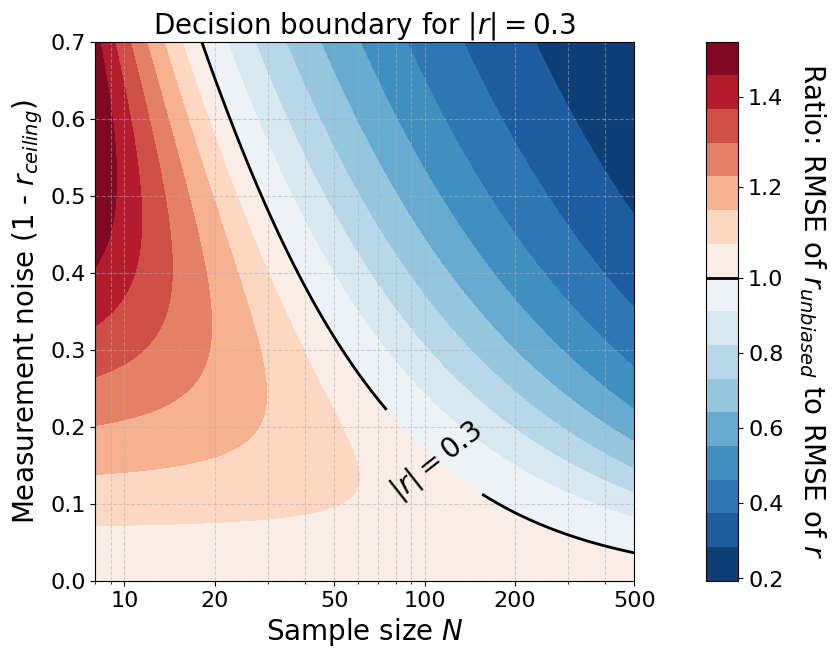

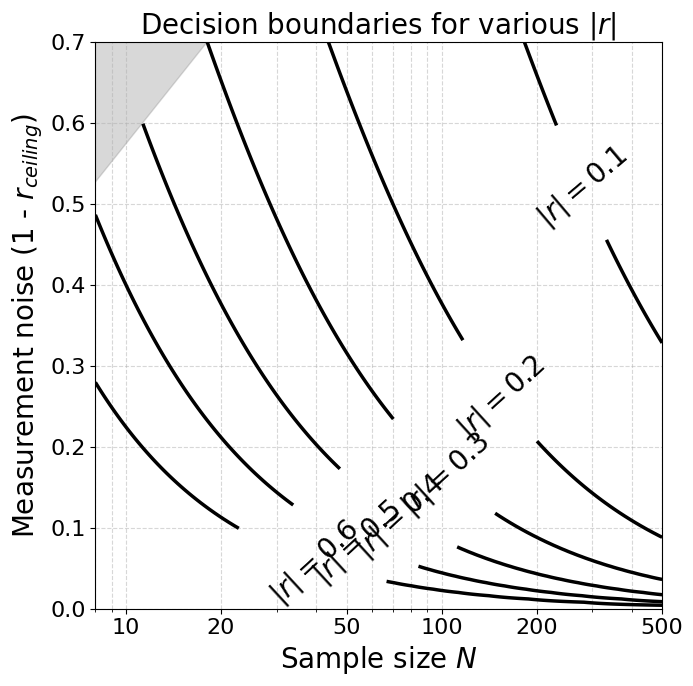

In [4]:
def calculate_rmse_ratio(n, r_ceiling, r):
    """
    Calculates the ratio of RMSE_unbiased to RMSE_raw based on:
    1. Var(r) ~= ((1 - r^2)^2) / (N - 1)
    2. RMSE_raw ~= sqrt(Var(r) + [rho * (1 - r_ceiling)]^2)
    3. RMSE_unbiased ~= sqrt(Var(r) / r_ceiling^2)
    where rho ~= r / r_ceiling
    """
    rho = r / r_ceiling
    var_r = ((1 - r**2)**2) / (n - 1)
    bias_squared = (rho * (1 - r_ceiling))**2
    rmse_raw = np.sqrt(var_r + bias_squared)
    rmse_unbiased = np.sqrt(var_r / (r_ceiling**2))
    
    return rmse_unbiased / rmse_raw


def find_termination_n(r_val):
    """
    Calculate the N value where the ratio = 1 contour terminates at r_ceiling = r_val.
    Derived analytically by setting ratio = 1 and r_ceiling = r.
    """
    return 1 + (1 - r_val) * (1 + r_val)**3 / r_val**2


def plot_rmse_ratio_heatmap(r_value):
    # --- Configuration ---
    n_min, n_max = 8, 500
    r_min, r_max = 0.3, 1.0

    # --- Data Generation ---
    n_range = np.logspace(np.log10(n_min), np.log10(n_max), 500)
    r_range = np.linspace(r_min, r_max, 500)
    n_grid, r_ceiling_grid = np.meshgrid(n_range, r_range)

    # Calculate the Ratio Matrix
    ratio = calculate_rmse_ratio(n_grid, r_ceiling_grid, r_value)

    # --- Plotting with gridspec for colorbar sizing ---
    fig = plt.figure(figsize=(9, 7))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 0.05], wspace=0.05)
    ax = fig.add_subplot(gs[0])
    cax = fig.add_subplot(gs[1])

    # Define custom levels to ensure equal banding density in both regions
    levels_blue = np.linspace(ratio.min(), 1.0, 10)
    levels_red = np.linspace(1.0, ratio.max(), 8)
    levels = np.unique(np.concatenate([levels_blue, levels_red]))

    # Create a TwoSlopeNorm centered at 1.0
    norm = TwoSlopeNorm(vmin=ratio.min(), vcenter=1.0, vmax=ratio.max())

    # Create the filled contour plot (Heatmap)
    cp = ax.contourf(n_grid, r_ceiling_grid, ratio, levels=levels, cmap='RdBu_r', norm=norm)

    # --- FIX FOR LINE AND LABEL ---
    ratio_line = ratio.copy()
    ratio_line[np.isclose(r_ceiling_grid, 1.0)] = np.nan

    line_contour = ax.contour(n_grid, r_ceiling_grid, ratio_line, levels=[1.0], colors=['black'], linewidths=2, linestyles='-')
    
    # --- ADD LABEL ---
    target_n = 40
    idx_n = np.abs(n_range - target_n).argmin()
    idx_r = np.abs(ratio[:, idx_n] - 1.0).argmin() 
    
    label_n = n_range[idx_n]
    label_r = r_range[idx_r]

    ax.clabel(
        line_contour, 
        inline=True, 
        fontsize=20, 
        fmt={1.0: f'$|r| = {r_value}$'}, 
        manual=[(label_n, label_r)],
        use_clabeltext=True,
        inline_spacing=15
    )

    # Add a colorbar
    cbar = fig.colorbar(cp, cax=cax, ticks=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2])
    cbar.set_label(r'Ratio: RMSE of $r_{unbiased}$ to RMSE of $r$', rotation=270, labelpad=32, fontsize=20)
    cbar.ax.tick_params(labelsize=16)
    cbar.ax.axhline(y=1.0, color='black', linestyle='-', linewidth=2)
    
    # --- Log Scale Configuration ---
    ax.set_xscale('log')
    ax.set_ylim(1.0, 0.3)

    ticks = [10, 20, 50, 100, 200, 500]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_major_formatter(ScalarFormatter())

    # --- Y-Axis Customization (Measurement Noise) ---
    def noise_formatter(x, pos):
        return f"{1 - x:.1f}"

    ax.yaxis.set_major_formatter(FuncFormatter(noise_formatter))
    
    r_ceil_ticks = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    ax.set_yticks(r_ceil_ticks)

    # Labels and Title
    ax.set_xlabel('Sample size $N$', fontsize=20)
    ax.set_ylabel(r'Measurement noise (1 - $r_{ceiling}$)', fontsize=20)
    ax.set_title(f'Decision boundary for $|r| = {r_value}$', fontsize=20)
    ax.tick_params(axis='both', labelsize=16)

    ax.grid(True, which="both", ls="--", linewidth=0.8, alpha=0.5)
    
    # Make plot square
    ax.set_box_aspect(1)
    
    plt.tight_layout()
    plt.show()


# --- CONTOUR PLOT FUNCTION ---

def solve_r_ceiling_for_fixed_n(n_target, n_grid, r_ceiling_grid, ratio_grid):
    """
    Finds the r_ceiling value where ratio=1.0 for a fixed N.
    Uses interpolation on the generated grid data.
    """
    n_values = n_grid[0, :]
    idx = np.abs(n_values - n_target).argmin()
    
    r_ceil_col = r_ceiling_grid[:, idx]
    ratio_col = ratio_grid[:, idx]
    
    sorted_indices = np.argsort(ratio_col)
    ratio_sorted = ratio_col[sorted_indices]
    r_ceil_sorted = r_ceil_col[sorted_indices]
    
    return np.interp(1.0, ratio_sorted, r_ceil_sorted)


def plot_rmse_ratio_contours():
    # --- Configuration ---
    r_naive_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
    spacings = [20, 10, 5, -5, -15, -20] 
    
    n_min, n_max = 8, 500
    r_ceil_min, r_ceil_max = 0.2, 1.0
    label_n_fixed = 10

    # --- Data Generation ---
    n_range = np.logspace(np.log10(n_min), np.log10(n_max), 200)
    r_ceil_range = np.linspace(r_ceil_min, r_ceil_max, 200)
    n_grid, r_ceiling_grid = np.meshgrid(n_range, r_ceil_range)

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(7, 7))

    # --- Add gray shading for impossible region ---
    # Find termination points for r=0.3 and r=0.4
    n_term_03 = find_termination_n(0.3)
    n_term_04 = find_termination_n(0.4)
    
    # Calculate line through termination points in LOG space (since x-axis is log)
    log_n_03 = np.log10(n_term_03)
    log_n_04 = np.log10(n_term_04)
    log_n_min = np.log10(n_min)
    
    slope_log = (0.4 - 0.3) / (log_n_04 - log_n_03)
    y_at_left = 0.3 + slope_log * (log_n_min - log_n_03)
    
    # Create polygon with both termination points explicitly included
    polygon_x = [n_min, n_term_03, n_term_04, n_min]
    polygon_y = [0.3, 0.3, 0.4, y_at_left]
    
    ax.fill(polygon_x, polygon_y, color='gray', alpha=0.3, zorder=0)

    for i, r_val in enumerate(r_naive_values):
        # Calculate ratio using the single function (inverted for this plot)
        ratio = 1.0 / calculate_rmse_ratio(n_grid, r_ceiling_grid, r_val)
        
        # --- Mask Invalid Regions ---
        ratio = np.ma.masked_where(r_ceiling_grid < r_val, ratio)
        
        # Plot the contour line where ratio = 1.0
        cs = ax.contour(
            n_grid, r_ceiling_grid, ratio, 
            levels=[1.0],   
            colors=['black'],
            linewidths=2.5, linestyles='-'
        )
        
        # Calculate label position
        label_r_ceil_pos = solve_r_ceiling_for_fixed_n(label_n_fixed, n_grid, r_ceiling_grid, ratio.filled(np.nan))
        
        # Add label at the calculated manual position
        if r_ceil_min <= label_r_ceil_pos <= r_ceil_max and label_r_ceil_pos >= r_val:
            ax.clabel(
                cs, 
                inline=True, 
                fontsize=20, 
                fmt={1.0: f'$|r| = {r_val}$'},
                manual=[(label_n_fixed, label_r_ceil_pos)],
                use_clabeltext=True,
                inline_spacing=spacings[i]
            )

    # --- Log Scale Configuration ---
    ax.set_xscale('log')
    
    ticks = [10, 20, 50, 100, 200, 500]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.xaxis.set_major_formatter(ScalarFormatter())

    # --- Y-Axis Customization (Measurement Noise) ---
    def noise_formatter(x, pos):
        return f"{1 - x:.1f}"

    ax.yaxis.set_major_formatter(FuncFormatter(noise_formatter))
    
    r_ceil_ticks = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    ax.set_yticks(r_ceil_ticks)

    # Labels and Title
    ax.set_xlabel(r'Sample size $N$', fontsize=20)
    ax.set_ylabel(r'Measurement noise (1 - $r_{ceiling}$)', fontsize=20)
    ax.set_title(r'Decision boundaries for various $|r|$', fontsize=20)
    ax.tick_params(axis='both', labelsize=16)
    
    # Reversed limits: 1.0 (noise 0) at bottom, 0.3 at top
    ax.set_ylim(1.0, 0.3)
    ax.set_xlim(n_min, n_max)

    ax.grid(True, which="both", ls="--", linewidth=0.8, alpha=0.5)
    
    # Make plot square
    ax.set_box_aspect(1)
    
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    plot_rmse_ratio_heatmap(r_value=0.3)
    plot_rmse_ratio_contours()

/var/folders/tv/bsvxxkg10s71322nv0drgww00000gn/T/ipykernel_45405/3918861911.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.94])


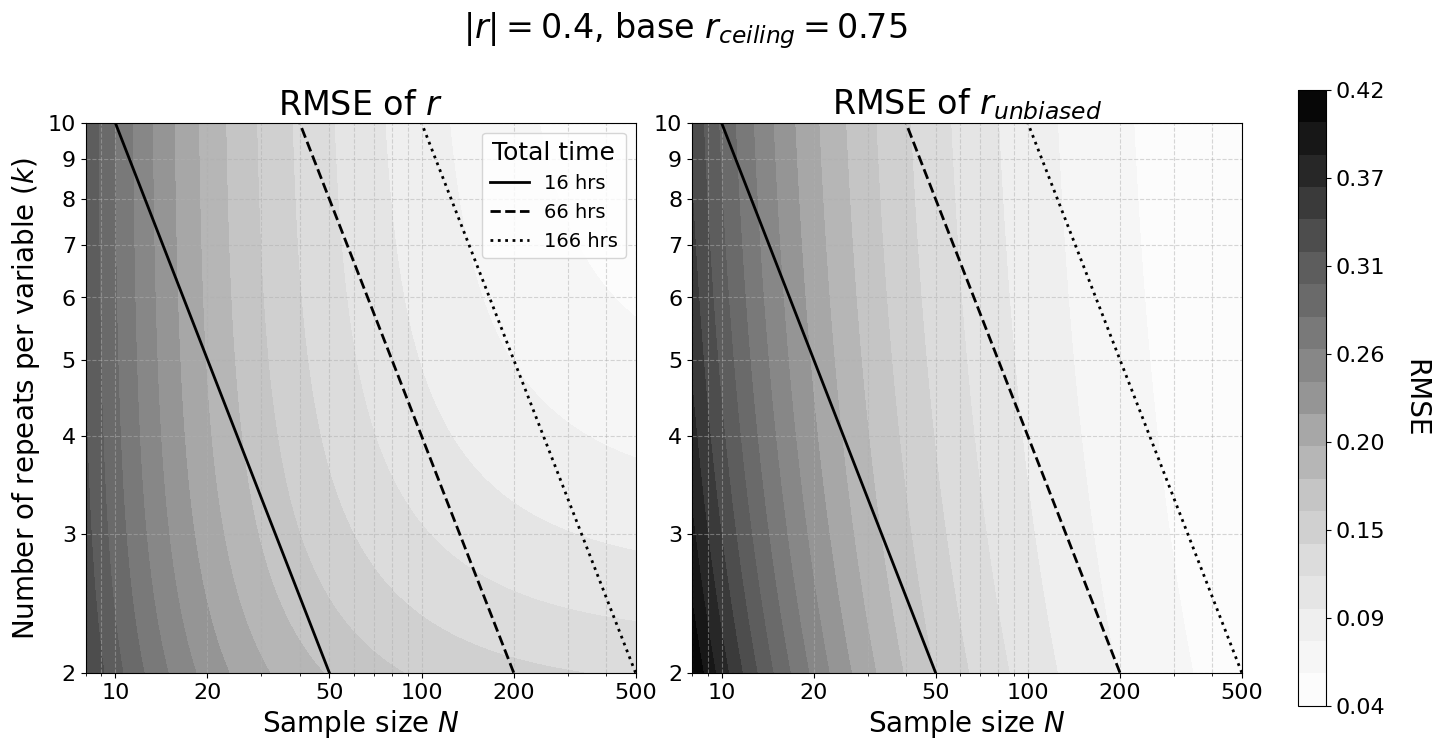

In [5]:
def calculate_r_ceiling_from_k(k, base_r_ceiling=0.75, base_k=2):
    """
    Calculate r_ceiling for a given number of repeats k.
    
    Given r_ceiling = between_var / (between_var + within_var/k),
    we derive the variance ratio from the base case and apply it to other k values.
    """
    variance_ratio = base_k * (1 - base_r_ceiling) / base_r_ceiling
    return 1 / (1 + variance_ratio / k)


def calculate_rmse_components(n, r_ceiling, r):
    """
    Calculates RMSE of r (raw) and RMSE of r_unbiased separately.
    """
    rho = r / r_ceiling
    var_r = ((1 - r**2)**2) / (n - 1)
    bias_squared = (rho * (1 - r_ceiling))**2
    mse_raw = var_r + bias_squared
    mse_unbiased = var_r / (r_ceiling**2)
    
    return np.sqrt(mse_raw), np.sqrt(mse_unbiased)


def calculate_n_for_time(total_time, k, base_time=20, time_per_repeat=10, base_k=2):
    """
    Calculate number of observers for a given total time and k repeats.
    """
    time_per_observer = base_time + (k - base_k) * time_per_repeat
    return total_time / time_per_observer


def plot_rmse_heatmaps(r_value, base_r_ceiling=0.75, base_k=2, 
                      iso_times=[4000, 6000, 10000], show_iso_temporal=True):
    """
    Plot side-by-side heatmaps for RMSE of r and RMSE of r_unbiased.
    """
    # --- Configuration ---
    n_min, n_max = 8, 500
    k_min, k_max = 2, 10

    # --- Data Generation ---
    n_range = np.logspace(np.log10(n_min), np.log10(n_max), 500)
    k_range = np.logspace(np.log10(k_min), np.log10(k_max), 500)  # Log-spaced k
    n_grid, k_grid = np.meshgrid(n_range, k_range)
    
    r_ceiling_grid = calculate_r_ceiling_from_k(k_grid, base_r_ceiling, base_k)
    rmse_raw, rmse_unbiased = calculate_rmse_components(n_grid, r_ceiling_grid, r_value)

    # --- Plotting with gridspec for colorbar sizing ---
    fig = plt.figure(figsize=(16, 8))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.15)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    cax = fig.add_subplot(gs[2])
    
    axes = [ax1, ax2]
    data_list = [rmse_raw, rmse_unbiased]
    titles = [r'RMSE of $r$', r'RMSE of $r_{unbiased}$']
    
    # Common colorbar range for comparison (linear scale)
    vmin = min(rmse_raw.min(), rmse_unbiased.min())
    vmax = max(rmse_raw.max(), rmse_unbiased.max())
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 20)
    
    # Iso-temporal contour styles
    iso_colors = ['black', 'black', 'black']
    iso_linestyles = ['-', '--', ':']
    
    for idx, (ax, data, title) in enumerate(zip(axes, data_list, titles)):
        # Create the filled contour plot
        cp = ax.contourf(n_grid, k_grid, data, levels=levels, cmap='Greys', norm=norm)
        
        # --- Add iso-temporal contours ---
        if show_iso_temporal:
            k_for_contour = np.linspace(k_min, k_max, 200)
            for i, (total_time, color, ls) in enumerate(zip(iso_times, iso_colors, iso_linestyles)):
                n_for_contour = calculate_n_for_time(total_time, k_for_contour)
                mask = (n_for_contour >= n_min) & (n_for_contour <= n_max)
                label = f'{total_time // 60:.0f} hrs' if idx == 0 else None
                ax.plot(n_for_contour[mask], k_for_contour[mask], 
                       color=color, linestyle=ls, linewidth=2, label=label)
        
        # --- Log Scale Configuration for X-axis ---
        ax.set_xscale('log')
        x_ticks = [10, 20, 50, 100, 200, 500]
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([str(t) for t in x_ticks])
        ax.xaxis.set_major_formatter(ScalarFormatter())

        # --- Log Scale Configuration for Y-axis ---
        ax.set_yscale('log')
        ax.set_ylim(k_min, k_max)
        k_ticks = [2, 3, 4, 5, 6, 7, 8, 9, 10]
        ax.set_yticks(k_ticks)
        ax.set_yticklabels([str(t) for t in k_ticks])
        ax.yaxis.set_major_formatter(ScalarFormatter())

        # Labels and Title
        ax.set_xlabel('Sample size $N$', fontsize=20)
        if idx == 0:
            ax.set_ylabel('Number of repeats per variable ($k$)', fontsize=20)
            legend = ax.legend(loc='upper right', fontsize=14, title='Total time')
            legend.get_title().set_fontsize(18)
        ax.set_title(title, fontsize=24)
        ax.tick_params(axis='both', labelsize=16)

        ax.grid(True, which="both", ls="--", linewidth=0.8, alpha=0.5)
        ax.set_box_aspect(1)
    
    # Add main title (higher and larger)
    fig.suptitle(rf'$|r| = {r_value}$, base $r_{{ceiling}} = {base_r_ceiling}$', fontsize=24, y=0.98)
    
    # Add colorbar
    cbar = fig.colorbar(cp, cax=cax)
    cbar.set_label('RMSE', rotation=270, labelpad=32, fontsize=20)

    # Linear tick locations
    tick_locations = np.linspace(vmin, vmax, 8)
    cbar.set_ticks(tick_locations)

    def rmse_formatter(x, pos):
        return f'{x:.2f}'

    cbar.ax.yaxis.set_major_formatter(FuncFormatter(rmse_formatter))
    cbar.ax.tick_params(labelsize=16)
    
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


def plot_all_rmse_heatmaps(r_values=[0.2, 0.3, 0.4, 0.5], base_r_ceiling=0.75, base_k=2,
                          iso_times=[4000, 6000, 10000], show_iso_temporal=True):
    """
    Plot RMSE heatmaps for multiple r values in a grid.
    """
    # --- Configuration ---
    n_min, n_max = 8, 500
    k_min, k_max = 2, 10

    # --- Data Generation ---
    n_range = np.logspace(np.log10(n_min), np.log10(n_max), 500)
    k_range = np.logspace(np.log10(k_min), np.log10(k_max), 500)  # Log-spaced k
    n_grid, k_grid = np.meshgrid(n_range, k_range)
    
    r_ceiling_grid = calculate_r_ceiling_from_k(k_grid, base_r_ceiling, base_k)

    # Calculate global min/max for consistent colorbar
    all_rmse_raw = []
    all_rmse_unbiased = []
    for r_value in r_values:
        rmse_raw, rmse_unbiased = calculate_rmse_components(n_grid, r_ceiling_grid, r_value)
        all_rmse_raw.append(rmse_raw)
        all_rmse_unbiased.append(rmse_unbiased)
    
    vmin = min(np.min(all_rmse_raw), np.min(all_rmse_unbiased))
    vmax = max(np.max(all_rmse_raw), np.max(all_rmse_unbiased))
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 20)

    # Iso-temporal contour styles
    iso_colors = ['black', 'black', 'black']
    iso_linestyles = ['-', '--', ':']

    # --- Plotting ---
    n_rows = len(r_values)
    fig = plt.figure(figsize=(14, 6.5 * n_rows))
    gs = fig.add_gridspec(n_rows, 3, width_ratios=[1, 1, 0.05], wspace=0.15, hspace=0.45)
    
    for row_idx, r_value in enumerate(r_values):
        rmse_raw, rmse_unbiased = all_rmse_raw[row_idx], all_rmse_unbiased[row_idx]
        data_list = [rmse_raw, rmse_unbiased]
        titles = [r'RMSE of $r$', r'RMSE of $r_{unbiased}$']
        
        for col_idx, (data, title) in enumerate(zip(data_list, titles)):
            ax = fig.add_subplot(gs[row_idx, col_idx])
            
            cp = ax.contourf(n_grid, k_grid, data, levels=levels, cmap='Greys', norm=norm)
            
            # --- Add iso-temporal contours ---
            if show_iso_temporal:
                k_for_contour = np.linspace(k_min, k_max, 200)
                for i, (total_time, color, ls) in enumerate(zip(iso_times, iso_colors, iso_linestyles)):
                    n_for_contour = calculate_n_for_time(total_time, k_for_contour)
                    mask = (n_for_contour >= n_min) & (n_for_contour <= n_max)
                    label = f'{total_time // 60:.0f} hrs' if (row_idx == 0 and col_idx == 0) else None
                    ax.plot(n_for_contour[mask], k_for_contour[mask], 
                           color=color, linestyle=ls, linewidth=2, label=label)
            
            # --- Log Scale Configuration for X-axis ---
            ax.set_xscale('log')
            x_ticks = [10, 20, 50, 100, 200, 500]
            ax.set_xticks(x_ticks)
            ax.set_xticklabels([str(t) for t in x_ticks])
            ax.xaxis.set_major_formatter(ScalarFormatter())

            # --- Log Scale Configuration for Y-axis ---
            ax.set_yscale('log')
            ax.set_ylim(k_min, k_max)
            k_ticks = [2, 3, 4, 5, 6, 7, 8, 9, 10]
            ax.set_yticks(k_ticks)
            ax.set_yticklabels([str(t) for t in k_ticks])
            ax.yaxis.set_major_formatter(ScalarFormatter())

            # Labels
            if row_idx == n_rows - 1:
                ax.set_xlabel('Sample size $N$', fontsize=20)
            if col_idx == 0:
                ax.set_ylabel('Number of repeats per variable ($k$)', fontsize=20)
            
            # Legend only on first plot
            if row_idx == 0 and col_idx == 0 and show_iso_temporal:
                legend = ax.legend(loc='upper right', fontsize=14, title='Total time')
                legend.get_title().set_fontsize(18)
            
            # Row title (centered above both panels)
            if col_idx == 0:
                ax.annotate(rf'$|r| = {r_value}$, base $r_{{ceiling}} = {base_r_ceiling}$', 
                           xy=(0.5, 1.18), xycoords='axes fraction',
                           fontsize=24, ha='center', va='bottom',
                           xytext=(1.08, 1.18), textcoords='axes fraction')
            
            ax.set_title(title, fontsize=24)
            ax.tick_params(axis='both', labelsize=16)

            ax.grid(True, which="both", ls="--", linewidth=0.8, alpha=0.5)
            ax.set_box_aspect(1)
    
    # Add shared colorbar
    cax = fig.add_subplot(gs[:, 2])
    cbar = fig.colorbar(cp, cax=cax)
    cbar.set_label('RMSE', rotation=270, labelpad=32, fontsize=20)
    
    # Linear tick locations
    tick_locations = np.linspace(vmin, vmax, 8)
    cbar.set_ticks(tick_locations)

    def rmse_formatter(x, pos):
        return f'{x:.2f}'

    cbar.ax.yaxis.set_major_formatter(FuncFormatter(rmse_formatter))
    cbar.ax.tick_params(labelsize=16)
    
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    plot_rmse_heatmaps(r_value=0.4, base_r_ceiling=0.75, base_k=2,
                      iso_times=[1000, 4000, 10000])

Below I test Jon's guess at the way r_ceiling scales with number of measurements:

In [2]:
calculate_r_ceiling_from_k(4, base_r_ceiling=0.75, base_k=2)

0.8571428571428571

In [3]:
1-(.25/1.7)

0.8529411764705882

In [4]:
calculate_r_ceiling_from_k(2, base_r_ceiling=0.75, base_k=2)

0.75

In [5]:
calculate_r_ceiling_from_k(6, base_r_ceiling=0.75, base_k=2)

0.8999999999999999

In [6]:
calculate_r_ceiling_from_k(10, base_r_ceiling=0.75, base_k=2)

0.9375

In [10]:
calculate_r_ceiling_from_k(8, base_r_ceiling=0.85, base_k=2)

0.9577464788732394